# Dashboard preditivo e-SUS APS – UBASF Antônio Gomes (Jaguaribe/CE)
**TCC – MBA em Data Science e Analytics (USP/Esalq)**
Autor: Ruan Carlos Damião Nogueira Rêgo · Orientador: Prof. Jacques Henrique Dias

Este notebook documenta: (1) a auditoria da base; (2) o *data wrangling*; (3) a análise exploratória;
(4) a construção da série semanal; (5) a comparação de modelos preditivos; (6) a implementação
manual do modelo vencedor, idêntica à função `fn_gerar_previsao` em PL/pgSQL do backend; (7) o agrupamento
não supervisionado dos perfis de demanda (K-means), idêntico à função `fn_gerar_perfis`.

In [1]:
# ---------------------------------------------------------------
# Etapa 0 – Bibliotecas e parâmetros gerais
# ---------------------------------------------------------------
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.api as sm
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing

warnings.filterwarnings('ignore')
ARQUIVO   = '../base_tcc_mba.xlsb'      # exportação do relatório gerencial de exames (e-SUS APS)
REGRAS    = 'regras_categoria.csv'      # mesma tabela de regras carregada no banco (regra_categoria)
HOLDOUT   = 8                           # semanas reservadas para teste
AZUL, LARANJA, CINZA, TEXTO = '#2a78d6', '#eb6834', '#8a8984', '#52514e'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.edgecolor': '#c9c8c3', 'axes.labelcolor': TEXTO,
                     'xtick.color': TEXTO, 'ytick.color': TEXTO, 'axes.grid': True, 'grid.color': '#ecebe7',
                     'grid.linewidth': 0.6, 'axes.axisbelow': True, 'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight'})

## 1. Auditoria da base

In [2]:
# ---------------------------------------------------------------
# Etapa 1 – Leitura e auditoria
# O arquivo .xlsb (Excel binário) é lido com o motor 'pyxlsb'.
# ---------------------------------------------------------------
bruto = pd.read_excel(ARQUIVO, engine='pyxlsb')
print('Dimensões:', bruto.shape)
print('Tipos:'); print(bruto.dtypes)
print('Valores ausentes por coluna:'); print(bruto.isna().sum())
print('Valores distintos:'); print(bruto.nunique())
# Linhas idênticas NÃO são erro: sem identificador de paciente, dois usuários com o mesmo
# perfil (dia, exame, atendimento, sexo e faixa) geram linhas iguais. Por isso não se deduplica.
print('Linhas idênticas:', bruto.duplicated().sum())

Dimensões: (8403, 5)
Tipos:
Dia                    int64
Exame                    str
Tipo de Atendimento      str
Sexo                     str
Faixa Etária             str
dtype: object
Valores ausentes por coluna:
Dia                    0
Exame                  0
Tipo de Atendimento    0
Sexo                   0
Faixa Etária           0
dtype: int64
Valores distintos:
Dia                    282
Exame                  191
Tipo de Atendimento      4
Sexo                     3
Faixa Etária            21
dtype: int64
Linhas idênticas: 968


## 2. Data wrangling (espelha o ETL do banco)

In [3]:
# ---------------------------------------------------------------
# Etapa 2 – Transformações (as mesmas regras de negócio do backend)
# ---------------------------------------------------------------
df = bruto.copy()

# RN-01: a coluna 'Dia' vem como número serial do Excel (dias desde 30/12/1899).
df['data'] = pd.to_datetime(df['Dia'], unit='D', origin='1899-12-30')

# Separação do código e da descrição do exame: 'CODIGO - DESCRIÇÃO'.
df['codigo']    = df['Exame'].str.split(' - ', n=1).str[0].str.strip()
df['descricao'] = df['Exame'].str.split(' - ', n=1).str[1].str.strip()

# RN-10: origem do código – SIGTAP (10 dígitos) ou código próprio do e-SUS (ABEX/ABPG).
df['origem'] = np.where(df['codigo'].str.fullmatch(r'\d{10}'), 'SIGTAP', 'e-SUS (código próprio)')

# RN-07: categoria temática – primeira regra (por prioridade) cujo padrão casar com a descrição.
regras = pd.read_csv(REGRAS, sep=';').sort_values('prioridade')
def classificar(desc):
    for _, r in regras.iterrows():
        if re.search(r['padrao'], desc.upper()):
            return r['categoria']
    return 'Outros'
mapa = {d: classificar(d) for d in df['descricao'].unique()}   # 191 exames -> categoria
df['categoria'] = df['descricao'].map(mapa)

# RN-08 e RN-09: flags de rastreamento oncológico (preventivo) e de pré-natal.
up = df['descricao'].str.upper()
df['rastreamento'] = up.str.contains('CITOPATOL|COLETA DE MATERIAL DO COLO|MAMOGRAFIA') & ~up.str.contains('BIOPSIA|ANATOMO')
df['pre_natal']    = up.str.contains('GESTANTE|OBSTETRIC|GRAVIDEZ|GONADOTROFINA')

# RN-05: ciclo de vida a partir da faixa etária original.
def ciclo(f):
    if f == 'Menos de 01 ano': return 'Criança (0–9)'
    idade = int(re.match(r'(\d+)', f).group(1))
    return ('Criança (0–9)' if idade < 10 else 'Adolescente (10–19)' if idade < 20
            else 'Adulto (20–59)' if idade < 60 else 'Idoso (60+)')
df['ciclo_vida'] = df['Faixa Etária'].map(ciclo)

# RN-04: início da semana epidemiológica (domingo).
df['inicio_semana'] = df['data'] - pd.to_timedelta((df['data'].dt.dayofweek + 1) % 7, unit='D')
print('Período:', df['data'].min().date(), 'a', df['data'].max().date())
print('Origem do código:'); print(df['origem'].value_counts())

Período: 2025-01-02 a 2026-06-03
Origem do código:
origem
SIGTAP                    6820
e-SUS (código próprio)    1583
Name: count, dtype: int64


## 3. Análise exploratória

In [4]:
# Medidas M01–M06 (mesmas definições do Quadro 2 / fn_dashboard)
total = len(df)
fm = df['Sexo'].value_counts()
kpis = {
  'M01 Total de exames': total,
  'M02 Média diária (dias com registro)': round(total / df['data'].nunique(), 1),
  'M03 % feminino (F ÷ (F+M))': round(100 * fm['Feminino'] / (fm['Feminino'] + fm['Masculino']), 1),
  'M04 Taxa de rastreamento (%)': round(100 * df['rastreamento'].mean(), 1),
  'M06 Exames do pré-natal': int(df['pre_natal'].sum()),
}
pd.Series(kpis)

M01 Total de exames                     8403.0
M02 Média diária (dias com registro)      29.8
M03 % feminino (F ÷ (F+M))                75.9
M04 Taxa de rastreamento (%)               9.1
M06 Exames do pré-natal                  921.0
dtype: float64

In [5]:
cat = df['categoria'].value_counts()
pd.DataFrame({'exames': cat, '%': (100 * cat / total).round(1)})

,exames,%
categoria,,
Doenças Infecciosas e IST,1653,19.7
Perfil Lipídico,1148,13.7
Função Renal e Urinária,1115,13.3
Saúde da Mulher e Pré-natal,1040,12.4
Hematologia,1002,11.9
Monitoramento Glicêmico,821,9.8
Função Hepática e Pancreática,620,7.4
Imagem e Métodos Gráficos,284,3.4
Ácido Úrico,240,2.9


In [6]:
# Série mensal: junho/2026 contém só 1 a 3 de junho (extração parcial) -> mês incompleto (RN-12).
mensal = df.groupby(df['data'].dt.to_period('M')).size()
mensal.to_frame('exames').T

data,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06
exames,337,347,480,928,1008,369,611,277,220,548,498,397,370,590,404,335,518,166


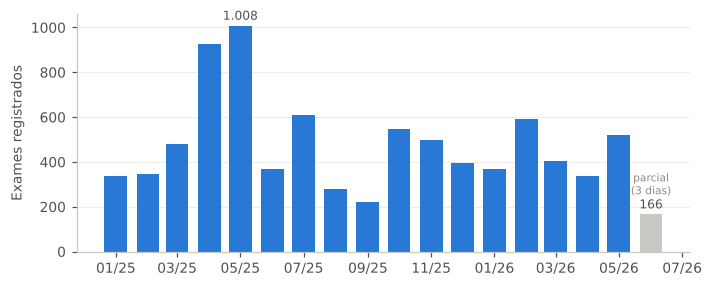

In [7]:
# Figura – série mensal com destaque para o mês incompleto
fig, ax = plt.subplots(figsize=(7.2, 2.8))
x = mensal.index.to_timestamp()
cores = [AZUL] * (len(mensal) - 1) + ['#c9c8c3']
ax.bar(x, mensal.values, width=22, color=cores)
for xi, yi in zip(x, mensal.values):
    if yi in (mensal.max(), mensal.iloc[-1]):
        ax.annotate(f'{yi:,}'.replace(',', '.'), (xi, yi), ha='center', va='bottom', fontsize=8, color=TEXTO, xytext=(0, 2), textcoords='offset points')
ax.set_ylabel('Exames registrados'); ax.grid(axis='x', visible=False)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%y'))
ax.text(x[-1], mensal.iloc[-1] + 90, 'parcial\n(3 dias)', ha='center', fontsize=7, color=CINZA)
plt.savefig('../figs/fig_serie_mensal.png'); plt.show()

## 4. Série semanal (unidade de modelagem)

In [8]:
# RN-12: apenas semanas completas (domingo a sábado) dentro da cobertura dos dados.
sem = df.groupby('inicio_semana').size()
sem = sem.reindex(pd.date_range(sem.index.min(), sem.index.max(), freq='7D'), fill_value=0)
ini, fim = df['data'].min(), df['data'].max()
serie = sem[(sem.index >= ini) & (sem.index + pd.Timedelta(days=6) <= fim)]
print(len(serie), 'semanas completas:', serie.index.min().date(), 'a', serie.index.max().date())
print(serie.describe().round(1))
print('Coeficiente de variação: %.1f%%' % (100 * serie.std() / serie.mean()))

73 semanas completas: 2025-01-05 a 2026-05-24
count     73.0
mean     112.5
std       72.3
min        2.0
25%       59.0
50%       97.0
75%      135.0
max      330.0
dtype: float64
Coeficiente de variação: 64.3%


## 5. Comparação de modelos (holdout das últimas 8 semanas)

In [9]:
# ---------------------------------------------------------------
# Etapa 5 – Treino/teste temporal: as 8 últimas semanas ficam fora do treino.
# ---------------------------------------------------------------
treino, teste = serie[:-HOLDOUT], serie[-HOLDOUT:]
def metricas(prev):
    e = teste.values - np.asarray(prev, dtype=float)
    return {'MAE': np.mean(np.abs(e)), 'RMSE': np.sqrt(np.mean(e ** 2)),
            'MAPE (%)': 100 * np.mean(np.abs(e) / teste.values)}

previsoes = {}
# (a) Ingênuo: repete a última observação
previsoes['Ingênuo'] = np.repeat(treino.iloc[-1], HOLDOUT)
# (b) Média móvel de 4 e 8 semanas
previsoes['Média móvel (4 sem.)'] = np.repeat(treino[-4:].mean(), HOLDOUT)
previsoes['Média móvel (8 sem.)'] = np.repeat(treino[-8:].mean(), HOLDOUT)
# (c) Ingênuo sazonal (mesma semana do ano anterior, defasagem 52)
previsoes['Ingênuo sazonal (52 sem.)'] = serie.shift(52)[-HOLDOUT:].values
# (d) Suavização exponencial simples – ETS(A,N,N)
ses = SimpleExpSmoothing(treino.values, initialization_method='estimated').fit()
previsoes['SES – ETS(A,N,N)'] = ses.forecast(HOLDOUT)
# (e) Holt – tendência aditiva, com e sem amortecimento
previsoes['Holt'] = ExponentialSmoothing(treino.values, trend='add', initialization_method='estimated').fit().forecast(HOLDOUT)
previsoes['Holt amortecido'] = ExponentialSmoothing(treino.values, trend='add', damped_trend=True,
                                                    initialization_method='estimated').fit().forecast(HOLDOUT)
# (f) Regressão de Poisson com tendência + termos de Fourier anuais (sazonalidade)
t = np.arange(len(serie))
def X(tt):
    w = 2 * np.pi * tt / 52.18
    return sm.add_constant(np.column_stack([tt, np.sin(w), np.cos(w)]))
poisson = sm.GLM(treino.values, X(t[:-HOLDOUT]), family=sm.families.Poisson()).fit()
previsoes['Regressão de Poisson'] = poisson.predict(X(t[-HOLDOUT:]))
print('Sobredispersão do Poisson (Pearson χ² / g.l.): %.1f' % (poisson.pearson_chi2 / poisson.df_resid))

tabela = pd.DataFrame({m: metricas(p) for m, p in previsoes.items()}).T.sort_values('MAE').round(2)
tabela

Sobredispersão do Poisson (Pearson χ² / g.l.): 43.9


,MAE,RMSE,MAPE (%)
Holt amortecido,31.62,51.40,37.37
"SES – ETS(A,N,N)",31.85,53.13,34.90
Holt,31.88,53.16,34.91
Média móvel (8 sem.),33.38,50.56,42.09
Média móvel (4 sem.),44.81,62.52,42.15
Ingênuo,60.38,76.62,52.52
Regressão de Poisson,62.31,66.60,88.47
Ingênuo sazonal (52 sem.),120.88,140.56,172.16


In [10]:
# Robustez: origem móvel (rolling origin), previsão 1 passo à frente nas últimas 16 semanas
def rolling(fn, k=16):
    erros = []
    for i in range(len(serie) - k, len(serie)):
        erros.append(serie.iloc[i] - fn(serie.iloc[:i]))
    erros = np.array(erros); obs = serie.iloc[-k:].values
    return {'MAE': np.mean(np.abs(erros)), 'MAPE (%)': 100 * np.mean(np.abs(erros) / obs)}
rob = pd.DataFrame({
  'Ingênuo': rolling(lambda s: s.iloc[-1]),
  'Média móvel (8 sem.)': rolling(lambda s: s[-8:].mean()),
  'SES – ETS(A,N,N)': rolling(lambda s: SimpleExpSmoothing(s.values, initialization_method='estimated').fit().forecast(1)[0]),
  'Holt amortecido': rolling(lambda s: ExponentialSmoothing(s.values, trend='add', damped_trend=True, initialization_method='estimated').fit().forecast(1)[0]),
}).T.round(2)
rob

,MAE,MAPE (%)
Ingênuo,58.00,65.30
Média móvel (8 sem.),50.52,70.00
"SES – ETS(A,N,N)",48.07,63.52
Holt amortecido,46.84,62.58


## 6. Implementação do modelo vencedor (idêntica ao PL/pgSQL)

In [11]:
# ---------------------------------------------------------------
# Etapa 6 – SES implementado 'à mão', linha a linha igual à fn_gerar_previsao:
#   nível l_t = α·y_t + (1-α)·l_{t-1}, com l_1 = y_1;
#   α por busca em grade (0,05..0,95; passo 0,01) minimizando a soma dos
#   quadrados dos erros 1 passo à frente; intervalo de 95% do ETS(A,N,N).
# ---------------------------------------------------------------
def ses_grade(y):
    y = np.asarray(y, dtype=float)
    melhor = None
    for a in np.round(np.arange(0.05, 0.951, 0.01), 2):
        nivel, sse = y[0], 0.0
        for obs in y[1:]:
            erro = obs - nivel          # erro de previsão 1 passo à frente
            sse += erro ** 2
            nivel = a * obs + (1 - a) * nivel
        if melhor is None or sse < melhor[1]:
            melhor = (a, sse, nivel)
    alpha, sse, nivel = melhor
    sigma = np.sqrt(sse / (len(y) - 1))
    return alpha, nivel, sigma

def intervalo(nivel, sigma, alpha, h):
    meia = 1.96 * sigma * np.sqrt(1 + (h - 1) * alpha ** 2)
    return max(0, nivel - meia), nivel + meia

# (i) desempenho da implementação manual no mesmo holdout
a_tr, n_tr, s_tr = ses_grade(treino)
print('Holdout – SES manual: α=%.2f' % a_tr, metricas(np.repeat(n_tr, HOLDOUT)))

# (ii) modelo final, treinado com todas as semanas (é o que o banco publica no dashboard)
alpha, nivel, sigma = ses_grade(serie)
print('Modelo final: α=%.2f | nível=%.1f | σ=%.2f' % (alpha, nivel, sigma))
prox = pd.date_range(serie.index[-1] + pd.Timedelta(days=7), periods=8, freq='7D')
prev_final = pd.DataFrame({'previsto': round(nivel, 1),
                           'limite_inf': [round(intervalo(nivel, sigma, alpha, h)[0], 1) for h in range(1, 9)],
                           'limite_sup': [round(intervalo(nivel, sigma, alpha, h)[1], 1) for h in range(1, 9)]}, index=prox)
prev_final

Holdout – SES manual: α=0.24 {'MAE': np.float64(31.819992348290185), 'RMSE': np.float64(53.08820392319315), 'MAPE (%)': np.float64(34.92028855060136)}
Modelo final: α=0.23 | nível=119.1 | σ=71.68


,previsto,limite_inf,limite_sup
2026-05-31,119.1,0,259.6
2026-06-07,119.1,0,263.3
2026-06-14,119.1,0,266.9
2026-06-21,119.1,0,270.3
2026-06-28,119.1,0,273.8
2026-07-05,119.1,0,277.1
2026-07-12,119.1,0,280.4
2026-07-19,119.1,0,283.6


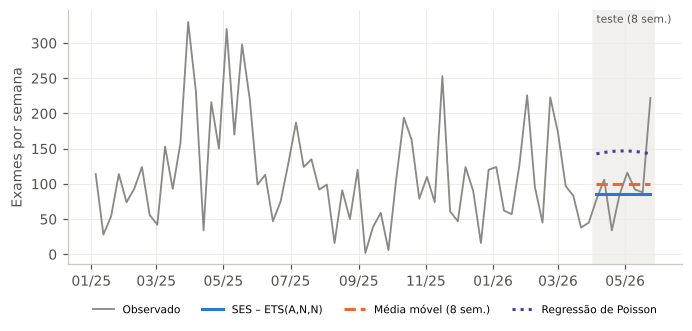

In [12]:
# Figura – holdout: observado x previsões dos melhores modelos
fig, ax = plt.subplots(figsize=(7.2, 3.0))
ax.plot(serie.index, serie.values, color=CINZA, lw=1.2, label='Observado')
ax.plot(teste.index, previsoes['SES – ETS(A,N,N)'], color=AZUL, lw=2, label='SES – ETS(A,N,N)')
ax.plot(teste.index, previsoes['Média móvel (8 sem.)'], color=LARANJA, lw=2, ls='--', label='Média móvel (8 sem.)')
ax.plot(teste.index, previsoes['Regressão de Poisson'], color='#4a3aa7', lw=2, ls=':', label='Regressão de Poisson')
ax.axvspan(teste.index[0] - pd.Timedelta(days=3), teste.index[-1] + pd.Timedelta(days=3), color='#f1f0ec', zorder=0)
ax.text(teste.index[0], ax.get_ylim()[1] * 0.95, 'teste (8 sem.)', fontsize=7, color=TEXTO)
ax.set_ylabel('Exames por semana'); ax.legend(frameon=False, fontsize=7, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%y'))
plt.savefig('../figs/fig_holdout.png'); plt.show()

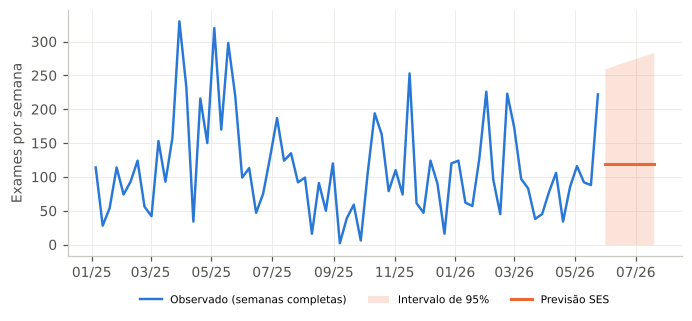

In [13]:
# Figura – série semanal + previsão de 8 semanas com intervalo de 95% (saída do dashboard)
fig, ax = plt.subplots(figsize=(7.2, 2.9))
ax.plot(serie.index, serie.values, color=AZUL, lw=1.6, label='Observado (semanas completas)')
ax.fill_between(prev_final.index, prev_final['limite_inf'], prev_final['limite_sup'], color=LARANJA, alpha=0.18, lw=0, label='Intervalo de 95%')
ax.plot(prev_final.index, prev_final['previsto'], color=LARANJA, lw=2, label='Previsão SES')
ax.set_ylabel('Exames por semana'); ax.legend(frameon=False, fontsize=7, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%y'))
plt.savefig('../figs/fig_previsao.png'); plt.show()

## 7. Perfis de demanda – agrupamento não supervisionado (K-means)

In [14]:
# ---------------------------------------------------------------
# Etapa 7 – Sem identificador de paciente, a unidade de análise é o PERFIL
# demográfico (sexo × faixa etária). Cada perfil é descrito pela composição
# dos exames que solicita: proporção de cada categoria temática (soma = 1).
# RN-14: entram apenas perfis com >= 30 exames.
# ---------------------------------------------------------------
df['perfil'] = df['Sexo'].str[0] + ' ' + df['Faixa Etária']
tab = pd.crosstab(df['perfil'], df['categoria'])
volume = tab.sum(axis=1)
eleg = volume[volume >= 30].index
comp = tab.loc[eleg].div(volume[eleg], axis=0)
comp = comp[sorted(comp.columns)]
Xp, wp = comp.values, volume[eleg].values
print('Perfis observados:', len(tab), '| elegíveis:', len(eleg),
      '| exames cobertos: %d (%.1f%%)' % (wp.sum(), 100 * wp.sum() / total))

Perfis observados: 43 | elegíveis: 34 | exames cobertos: 8225 (97.9%)


In [15]:
# K-means com inicialização determinística (idêntica à fn_gerar_perfis):
# 1º centróide = perfil de maior volume; demais = perfil mais distante (farthest-first);
# atualização pelo algoritmo de Lloyd até não haver mudança de grupo.
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.cluster import KMeans
def kmeans_det(X, k, w, iters=100):
    cent = [X[np.argmax(w)]]
    while len(cent) < k:
        d2 = np.min([((X - c) ** 2).sum(1) for c in cent], axis=0)
        cent.append(X[np.argmax(d2)])
    cent = np.array(cent); lab = np.full(len(X), -1)
    for _ in range(iters):
        novo = np.argmin(((X[:, None, :] - cent[None]) ** 2).sum(2), axis=1)   # atribuição
        if (novo == lab).all(): break
        lab = novo
        cent = np.array([X[lab == j].mean(0) for j in range(k)])               # atualização
    return lab, cent

# RN-15: k entre 2 e 6 escolhido pelo maior coeficiente de silhueta
sil = {}
for k in range(2, 7):
    lab_k, _ = kmeans_det(Xp, k, wp)
    sil[k] = silhouette_score(Xp, lab_k)
sil_tab = pd.Series(sil, name='silhueta').round(3); print(sil_tab)
k_best = int(sil_tab.idxmax())
lab, cent = kmeans_det(Xp, k_best, wp)
# Conferência: o K-means++ do scikit-learn com 100 inicializações encontra a mesma partição?
km = KMeans(k_best, n_init=100, random_state=0).fit(Xp)
print('k escolhido:', k_best, '| ARI vs scikit-learn:', adjusted_rand_score(lab, km.labels_))

2    0.485
3    0.470
4    0.496
5    0.459
6    0.443
Name: silhueta, dtype: float64


k escolhido: 4 | ARI vs scikit-learn: 1.0


In [16]:
# Grupos renumerados por volume de exames (1 = maior) e descrição
ordem = pd.Series(wp).groupby(lab).sum().sort_values(ascending=False).index
ren = {g: i + 1 for i, g in enumerate(ordem)}
grupo = pd.Series([ren[g] for g in lab], index=eleg, name='grupo')
geral = (tab.sum() / tab.values.sum())[comp.columns]
centro = pd.DataFrame(cent, columns=comp.columns).rename(index=ren).sort_index()
resumo_g = pd.DataFrame({'perfis': grupo.value_counts().sort_index(),
                         'exames': pd.Series(wp, index=eleg).groupby(grupo).sum(),
                         'destaque': (centro - geral).idxmax(axis=1),
                         'p.p. acima da média': (100 * (centro - geral).max(axis=1)).round(1)})
for g in resumo_g.index:
    print(g, '->', '; '.join(grupo[grupo == g].index))
resumo_g

1 -> F 15 a 19 anos; F 20 a 24 anos; F 25 a 29 anos; F 30 a 34 anos; F 35 a 39 anos
2 -> F 03 anos; F 04 anos; F 05 a 09 anos; F 65 a 69 anos; F 70 a 74 anos; F 75 a 79 anos; F 80 anos ou mais; M 02 anos; M 05 a 09 anos; M 10 a 14 anos; M 40 a 44 anos; M 45 a 49 anos; M 50 a 54 anos; M 55 a 59 anos; M 60 a 64 anos; M 65 a 69 anos; M 70 a 74 anos; M 75 a 79 anos; M 80 anos ou mais
3 -> F 40 a 44 anos; F 45 a 49 anos; F 50 a 54 anos; F 55 a 59 anos; F 60 a 64 anos
4 -> F 10 a 14 anos; M 15 a 19 anos; M 20 a 24 anos; M 25 a 29 anos; M 30 a 34 anos


,perfis,exames,destaque,p.p. acima da média
1,5,3117,Doenças Infecciosas e IST,22.0
2,19,2643,Perfil Lipídico,8.9
3,5,2004,Saúde da Mulher e Pré-natal,13.4
4,5,461,Perfil Lipídico,3.4


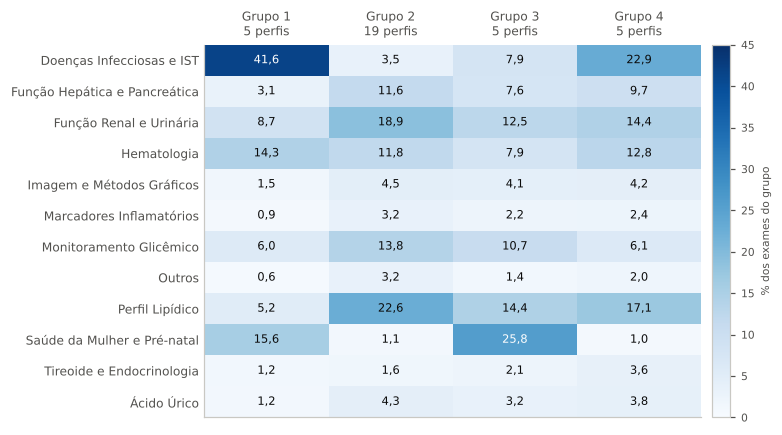

In [17]:
# Figura – composição média (centróide) de cada grupo, em % dos exames
M = 100 * centro.values.T                      # linhas = categorias, colunas = grupos
fig, ax = plt.subplots(figsize=(6.2, 4.4))
im = ax.imshow(M, cmap='Blues', aspect='auto', vmin=0, vmax=45)
ax.set_yticks(range(len(centro.columns))); ax.set_yticklabels(centro.columns, fontsize=8)
ax.set_xticks(range(len(centro)))
ax.set_xticklabels([f'Grupo {g}\n{resumo_g.loc[g, "perfis"]} perfis' for g in centro.index], fontsize=8)
ax.xaxis.tick_top()
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, i, f'{M[i, j]:.1f}'.replace('.', ','), ha='center', va='center', fontsize=7.5,
                color='white' if M[i, j] > 25 else '#0b0b0b')
ax.grid(False); ax.tick_params(length=0)
cb = plt.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.set_label('% dos exames do grupo', fontsize=7); cb.ax.tick_params(labelsize=7)
plt.savefig('../figs/fig_clusters.png'); plt.show()

In [18]:
# Exporta resultados para o texto do TCC
tabela.to_csv('resultados_holdout.csv'); rob.to_csv('resultados_rolling.csv'); prev_final.to_csv('previsao_final.csv')
pd.DataFrame({'exames': cat, 'pct': (100 * cat / total).round(1)}).to_csv('categorias.csv')
sil_tab.to_csv('silhueta_k.csv'); resumo_g.to_csv('perfis_grupos.csv'); grupo.to_csv('perfis_membros.csv')